<a href="https://colab.research.google.com/github/zelga-code/Tugas-Probabilitas-phyton/blob/main/Kode_Laporan_Probabilitas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 2. Contoh penggunaan library (Gambar 2.1)

In [1]:
import math, statistics, random, itertools
from fractions import Fraction
import numpy as np
import pandas as pd
import sympy as sp
from scipy import stats

print("math.comb(5, 2)           :", math.comb(5, 2))
print("math.factorial(5)         :", math.factorial(5))
print("Fraction(3, 12)           :", Fraction(3, 12))
print("itertools.permutations    :", len(list(itertools.permutations("ABC"))))
random.seed(1)
print("random.choice             :", random.choice(["Kepala", "Ekor"]))
data = [2, 4, 4, 4, 5, 5, 7, 9]
print("statistics.mean           :", statistics.mean(data))
print("statistics.pvariance      :", statistics.pvariance(data))
print("numpy mean / var          :", np.mean(data), "/", np.var(data))
print("pandas describe (std)     :", round(pd.Series(data).std(), 4))
print("scipy norm.cdf(1.96)      :", round(stats.norm.cdf(1.96), 4))
print("sympy Rational 1/3+1/6    :", sp.Rational(1, 3) + sp.Rational(1, 6))

math.comb(5, 2)           : 10
math.factorial(5)         : 120
Fraction(3, 12)           : 1/4
itertools.permutations    : 6
random.choice             : Kepala
statistics.mean           : 5
statistics.pvariance      : 4
numpy mean / var          : 5.0 / 4.0
pandas describe (std)     : 2.1381
scipy norm.cdf(1.96)      : 0.975
sympy Rational 1/3+1/6    : 1/2


## A1. Dua dadu

In [2]:
from itertools import product
from fractions import Fraction
import random

ruang = list(product(range(1, 7), repeat=2))
kejadian = [s for s in ruang if sum(s) == 7]
p_hitung = Fraction(len(kejadian), len(ruang))
print("Jumlah ruang sampel   :", len(ruang))
print("Kejadian jumlah = 7   :", len(kejadian))
print("P(jumlah 7) hitung    :", p_hitung, "=", round(float(p_hitung), 4))

random.seed(1)
N = 100000
hasil = sum(sum(random.choices(range(1, 7), k=2)) == 7 for _ in range(N))
print("P(jumlah 7) simulasi  :", round(hasil / N, 4))

Jumlah ruang sampel   : 36
Kejadian jumlah = 7   : 6
P(jumlah 7) hitung    : 1/6 = 0.1667
P(jumlah 7) simulasi  : 0.1674


## A2. Kombinasi dan permutasi

In [3]:
import math
from scipy.stats import hypergeom

total = math.comb(10, 4)
tepat2 = math.comb(6, 2) * math.comb(4, 2)
print("Jumlah cara pilih tim    :", total)
print("Cara tepat 2 anak RPL    :", tepat2)
print("P(tepat 2 RPL) hitung    :", round(tepat2 / total, 4))
print("P(tepat 2 RPL) scipy     :", round(hypergeom.pmf(2, 10, 6, 4), 4))
print("Susunan 3 jabatan (perm) :", math.perm(10, 3))

Jumlah cara pilih tim    : 210
Cara tepat 2 anak RPL    : 90
P(tepat 2 RPL) hitung    : 0.4286
P(tepat 2 RPL) scipy     : 0.4286
Susunan 3 jabatan (perm) : 720


## A3. Probabilitas bersyarat (pandas)

In [4]:
import pandas as pd

rutin = ["Ya"] * 100 + ["Tidak"] * 100
lulus = ["Ya"] * 90 + ["Tidak"] * 10 + ["Ya"] * 40 + ["Tidak"] * 60
df = pd.DataFrame({"Rutin": rutin, "Lulus": lulus})

print(pd.crosstab(df["Rutin"], df["Lulus"], margins=True))
p_lulus = (df["Lulus"] == "Ya").mean()
p_l_r = (df[df["Rutin"] == "Ya"]["Lulus"] == "Ya").mean()
p_l_t = (df[df["Rutin"] == "Tidak"]["Lulus"] == "Ya").mean()
p_r_l = (df[df["Lulus"] == "Ya"]["Rutin"] == "Ya").mean()
print("P(Lulus)         =", round(p_lulus, 4))
print("P(Lulus | Rutin) =", round(p_l_r, 4))
print("P(Lulus | Tidak) =", round(p_l_t, 4))
print("P(Rutin | Lulus) =", round(p_r_l, 4))

Lulus  Tidak   Ya  All
Rutin                 
Tidak     60   40  100
Ya        10   90  100
All       70  130  200
P(Lulus)         = 0.65
P(Lulus | Rutin) = 0.9
P(Lulus | Tidak) = 0.4
P(Rutin | Lulus) = 0.6923


## A4. Teorema Bayes (spam)

In [5]:
import numpy as np

p_spam = 0.30
p_g_spam = 0.60
p_g_ham = 0.05
p_gratis = p_g_spam * p_spam + p_g_ham * (1 - p_spam)
p_spam_g = (p_g_spam * p_spam) / p_gratis
print("P(gratis)      =", round(p_gratis, 4))
print("P(Spam | gratis) =", round(p_spam_g, 4))

rng = np.random.default_rng(1)
N = 500000
spam = rng.random(N) < p_spam
gratis = np.where(spam, rng.random(N) < p_g_spam,
                  rng.random(N) < p_g_ham)
print("Simulasi P(Spam | gratis) =", round(spam[gratis].mean(), 4))

P(gratis)      = 0.215
P(Spam | gratis) = 0.8372
Simulasi P(Spam | gratis) = 0.8366


## A5. Kejadian bebas dan gabungan

In [6]:
import numpy as np

pA, pB = 0.95, 0.90
keduanya = pA * pB
minimal1 = pA + pB - keduanya
tepat1 = pA * (1 - pB) + (1 - pA) * pB
mati_semua = (1 - pA) * (1 - pB)
print("P(A dan B aktif)     =", round(keduanya, 4))
print("P(minimal satu aktif) =", round(minimal1, 4))
print("P(tepat satu aktif)   =", round(tepat1, 4))
print("P(keduanya mati)      =", round(mati_semua, 4))

rng = np.random.default_rng(5)
N = 1_000_000
A = rng.random(N) < pA
B = rng.random(N) < pB
print("Simulasi minimal satu =", round((A | B).mean(), 4))
print("Simulasi tepat satu   =", round((A ^ B).mean(), 4))
print("Simulasi keduanya mati =", round((~A & ~B).mean(), 4))

P(A dan B aktif)     = 0.855
P(minimal satu aktif) = 0.995
P(tepat satu aktif)   = 0.14
P(keduanya mati)      = 0.005
Simulasi minimal satu = 0.9951
Simulasi tepat satu   = 0.1403
Simulasi keduanya mati = 0.0049


## A6. Monty Hall

In [7]:
import random
random.seed(7)

def main(ganti, N=100000):
    menang = 0
    for _ in range(N):
        hadiah = random.randint(0, 2)
        pilih = random.randint(0, 2)
        buka = random.choice([p for p in range(3) if p not in (hadiah, pilih)])
        if ganti:
            pilih = [p for p in range(3) if p not in (pilih, buka)][0]
        menang += (pilih == hadiah)
    return menang / N

print("Teori : tetap = 0.3333 | ganti = 0.6667")
print("Simulasi: tetap =", round(main(False), 4))
print("Simulasi: ganti =", round(main(True), 4))

Teori : tetap = 0.3333 | ganti = 0.6667
Simulasi: tetap = 0.3322
Simulasi: ganti = 0.6656


## A7. Paradoks ulang tahun

n=10 | rumus=0.1169 | simulasi=0.1166
n=20 | rumus=0.4114 | simulasi=0.4107
n=23 | rumus=0.5073 | simulasi=0.5041
n=30 | rumus=0.7063 | simulasi=0.7101
n=40 | rumus=0.8912 | simulasi=0.8903
n=50 | rumus=0.9704 | simulasi=0.9690


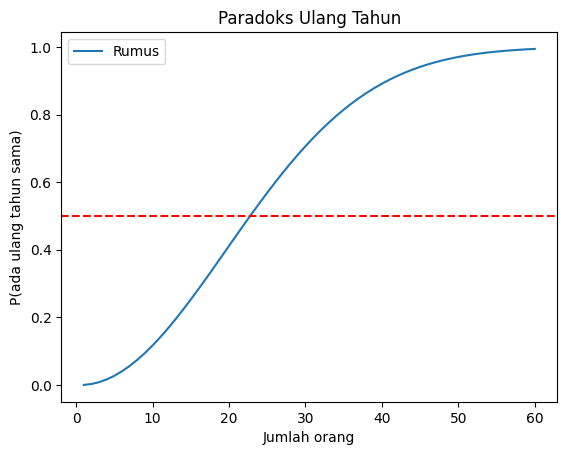

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def p_sama(n, hari=365):
    p_beda = 1.0
    for i in range(n):
        p_beda *= (hari - i) / hari
    return 1 - p_beda

rng = np.random.default_rng(3)
def simulasi(n, N=20000):
    hit = 0
    for _ in range(N):
        if len(set(rng.integers(0, 365, n))) < n:
            hit += 1
    return hit / N

for n in [10, 20, 23, 30, 40, 50]:
    print(f"n={n:2d} | rumus={p_sama(n):.4f} | simulasi={simulasi(n):.4f}")

n_ = range(1, 61)
plt.plot(n_, [p_sama(n) for n in n_], label="Rumus")
plt.axhline(0.5, color="red", linestyle="--")
plt.xlabel("Jumlah orang")
plt.ylabel("P(ada ulang tahun sama)")
plt.title("Paradoks Ulang Tahun")
plt.legend()
plt.show()

## A8. Hukum bilangan besar

Lemparan ke-   10 : proporsi kepala = 0.7000
Lemparan ke-  100 : proporsi kepala = 0.4700
Lemparan ke- 1000 : proporsi kepala = 0.4840
Lemparan ke-10000 : proporsi kepala = 0.4980


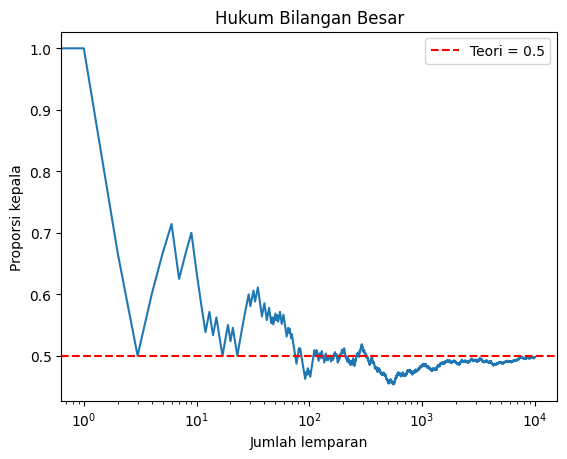

In [9]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(10)
lempar = rng.integers(0, 2, 10000)
proporsi = np.cumsum(lempar) / np.arange(1, 10001)
for n in [10, 100, 1000, 10000]:
    print(f"Lemparan ke-{n:5d} : proporsi kepala = {proporsi[n-1]:.4f}")

plt.plot(proporsi)
plt.axhline(0.5, color="red", linestyle="--", label="Teori = 0.5")
plt.xscale("log")
plt.xlabel("Jumlah lemparan")
plt.ylabel("Proporsi kepala")
plt.title("Hukum Bilangan Besar")
plt.legend()
plt.show()

## A9. Permutasi PIN

In [10]:
import math
from itertools import permutations

pin_ulang = 10 ** 4
pin_unik = math.perm(10, 4)
cek = sum(1 for _ in permutations(range(10), 4))
print("PIN 4 digit boleh angka sama :", pin_ulang)
print("PIN 4 digit angka beda semua :", pin_unik, "(cek itertools:", cek, ")")
print("P(tebak benar 1x), boleh sama:", 1 / pin_ulang)
print("P(tebak benar 1x), beda semua:", round(1 / pin_unik, 6))
print("P(benar dalam 3x coba)       :", round(3 / pin_unik, 6))

PIN 4 digit boleh angka sama : 10000
PIN 4 digit angka beda semua : 5040 (cek itertools: 5040 )
P(tebak benar 1x), boleh sama: 0.0001
P(tebak benar 1x), beda semua: 0.000198
P(benar dalam 3x coba)       : 0.000595


## A10. Probabilitas total dan Bayes

In [11]:
import pandas as pd

df = pd.DataFrame({
    "Mesin": ["M1", "M2", "M3"],
    "P(M)": [0.50, 0.30, 0.20],
    "P(Cacat|M)": [0.02, 0.03, 0.05],
})
df["P(M dan Cacat)"] = df["P(M)"] * df["P(Cacat|M)"]
p_cacat = df["P(M dan Cacat)"].sum()
df["P(M|Cacat)"] = df["P(M dan Cacat)"] / p_cacat
print(df.round(4).to_string(index=False))
print("P(Cacat) total =", round(p_cacat, 4))

Mesin  P(M)  P(Cacat|M)  P(M dan Cacat)  P(M|Cacat)
   M1   0.5        0.02           0.010      0.3448
   M2   0.3        0.03           0.009      0.3103
   M3   0.2        0.05           0.010      0.3448
P(Cacat) total = 0.029


## B1. Binomial

P(X = 3) = 0.2503
P(X >= 5) = 0.0781
Rata-rata = 2.5 | Varians = 1.875
Simulasi : rata-rata = 2.503 | varians = 1.877


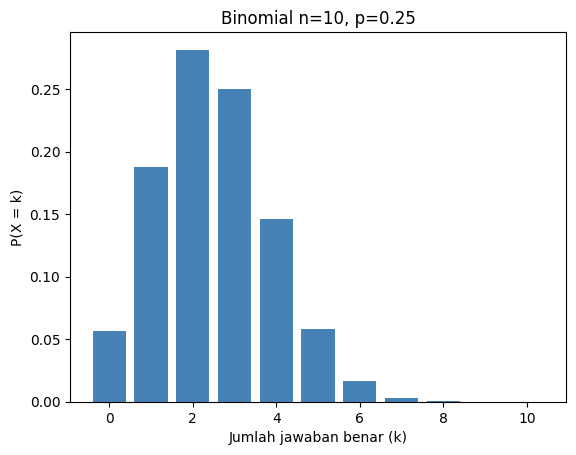

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n, p = 10, 0.25
X = binom(n, p)
print("P(X = 3) =", round(X.pmf(3), 4))
print("P(X >= 5) =", round(X.sf(4), 4))
print("Rata-rata =", X.mean(), "| Varians =", X.var())
sim = np.random.default_rng(2).binomial(n, p, 100000)
print("Simulasi : rata-rata =", round(sim.mean(), 3),
      "| varians =", round(sim.var(), 3))

k = np.arange(0, n + 1)
plt.bar(k, X.pmf(k), color="steelblue")
plt.xlabel("Jumlah jawaban benar (k)")
plt.ylabel("P(X = k)")
plt.title("Binomial n=10, p=0.25")
plt.show()

## B2. Poisson

P(X = 6) = 0.1042
P(X > 8) = 0.0214
Rata-rata = 4.0 | Varians = 4.0
Simulasi : rata-rata = 3.999 | varians = 4.0


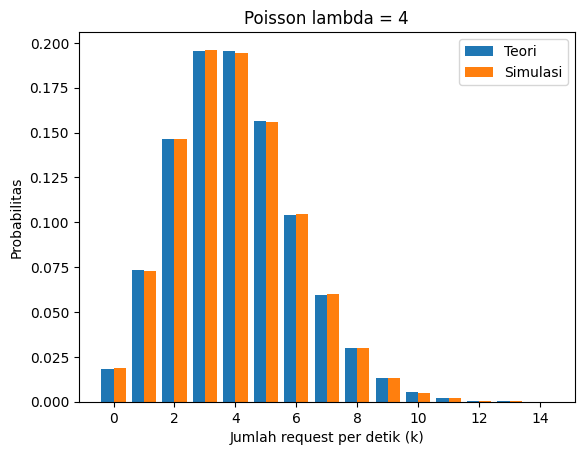

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

lam = 4
X = poisson(lam)
print("P(X = 6) =", round(X.pmf(6), 4))
print("P(X > 8) =", round(X.sf(8), 4))
print("Rata-rata =", X.mean(), "| Varians =", X.var())
sim = np.random.default_rng(4).poisson(lam, 100000)
print("Simulasi : rata-rata =", round(sim.mean(), 3),
      "| varians =", round(sim.var(), 3))

k = np.arange(0, 15)
plt.bar(k - 0.2, X.pmf(k), width=0.4, label="Teori")
plt.bar(k + 0.2, [(sim == i).mean() for i in k], width=0.4, label="Simulasi")
plt.xlabel("Jumlah request per detik (k)")
plt.ylabel("Probabilitas")
plt.title("Poisson lambda = 4")
plt.legend()
plt.show()

## B3. Geometrik

In [14]:
import numpy as np
from scipy.stats import geom

p = 0.7
X = geom(p)
print("P(X = 3) =", round(X.pmf(3), 4), " (berhasil di percobaan ke-3)")
print("P(X <= 2) =", round(X.cdf(2), 4), " (berhasil paling lama 2 kali)")
print("Rata-rata =", round(X.mean(), 4), "| Varians =", round(X.var(), 4))
sim = np.random.default_rng(6).geometric(p, 100000)
print("Simulasi : P(X=3) =", round((sim == 3).mean(), 4))
print("Simulasi : rata-rata =", round(sim.mean(), 4),
      "| varians =", round(sim.var(), 4))

P(X = 3) = 0.063  (berhasil di percobaan ke-3)
P(X <= 2) = 0.91  (berhasil paling lama 2 kali)
Rata-rata = 1.4286 | Varians = 0.6122
Simulasi : P(X=3) = 0.0627
Simulasi : rata-rata = 1.43 | varians = 0.6162


## B4. Binomial negatif

In [15]:
import math
import numpy as np
from scipy.stats import nbinom

r, p = 3, 0.4
manual = math.comb(5, 2) * p**3 * (1 - p)**3
scipy_ = nbinom.pmf(3, r, p)
print("P(total 6 tes) manual =", round(manual, 5))
print("P(total 6 tes) scipy  =", round(scipy_, 5))
print("Rata-rata tes =", round(nbinom.mean(r, p) + r, 2))
print("Varians tes   =", round(nbinom.var(r, p), 4))
sim = np.random.default_rng(8).negative_binomial(r, p, 100000) + r
print("Simulasi : P(6 tes) =", round((sim == 6).mean(), 5))
print("Simulasi : rata-rata =", round(sim.mean(), 3))

P(total 6 tes) manual = 0.13824
P(total 6 tes) scipy  = 0.13824
Rata-rata tes = 7.5
Varians tes   = 11.25
Simulasi : P(6 tes) = 0.1365
Simulasi : rata-rata = 7.513


## B5. Hipergeometrik

P(tepat 1 rusak) manual = 0.4696
P(tepat 1 rusak) scipy  = 0.4696
P(minimal 1 rusak)      = 0.7183
Rata-rata = 1.0 | Varians = 0.6316


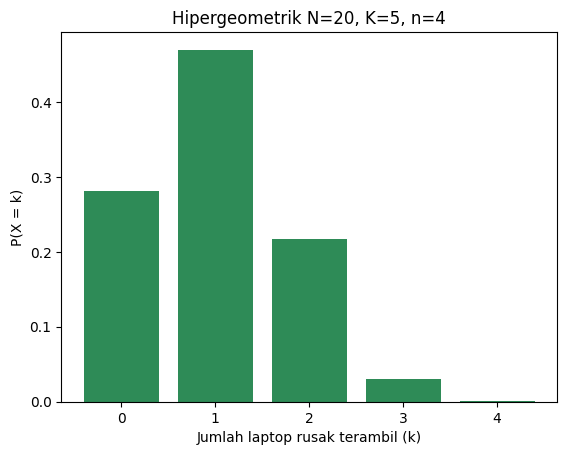

In [16]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import hypergeom

N, K, n = 20, 5, 4
manual = math.comb(5, 1) * math.comb(15, 3) / math.comb(20, 4)
X = hypergeom(N, K, n)
print("P(tepat 1 rusak) manual =", round(manual, 4))
print("P(tepat 1 rusak) scipy  =", round(X.pmf(1), 4))
print("P(minimal 1 rusak)      =", round(1 - X.pmf(0), 4))
print("Rata-rata =", X.mean(), "| Varians =", round(X.var(), 4))

k = np.arange(0, 5)
plt.bar(k, X.pmf(k), color="seagreen")
plt.xlabel("Jumlah laptop rusak terambil (k)")
plt.ylabel("P(X = k)")
plt.title("Hipergeometrik N=20, K=5, n=4")
plt.show()

## B6. Normal

P(X < 250) = 0.9522
P(170 < X < 230) = 0.6827
P(X > 260) = 0.0228
Persentil ke-95 = 249.35 ms


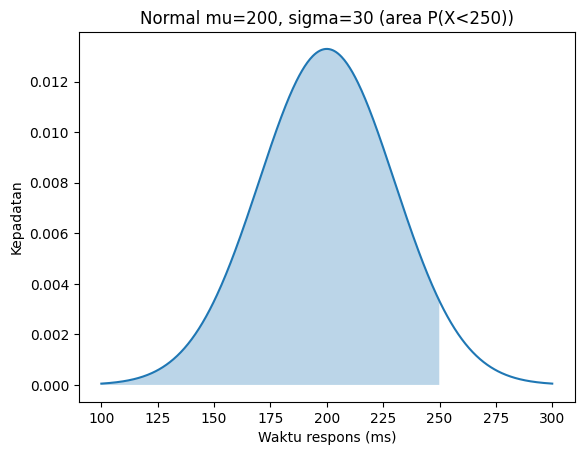

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu, sd = 200, 30
X = norm(mu, sd)
print("P(X < 250) =", round(X.cdf(250), 4))
print("P(170 < X < 230) =", round(X.cdf(230) - X.cdf(170), 4))
print("P(X > 260) =", round(X.sf(260), 4))
print("Persentil ke-95 =", round(X.ppf(0.95), 2), "ms")

x = np.linspace(100, 300, 500)
plt.plot(x, X.pdf(x))
plt.fill_between(x, X.pdf(x), where=(x < 250), alpha=0.3)
plt.xlabel("Waktu respons (ms)")
plt.ylabel("Kepadatan")
plt.title("Normal mu=200, sigma=30 (area P(X<250))")
plt.show()

## B7. Eksponensial

P(X > 80) = 0.2019
P(X < 30) = 0.4512
P(X>100 | X>50) = 0.3679 (= P(X>50) = 0.3679 )
Sympy: E(X) = 50 | Var(X) = 2500
Simulasi: rata-rata = 49.96 | varians = 2504.2


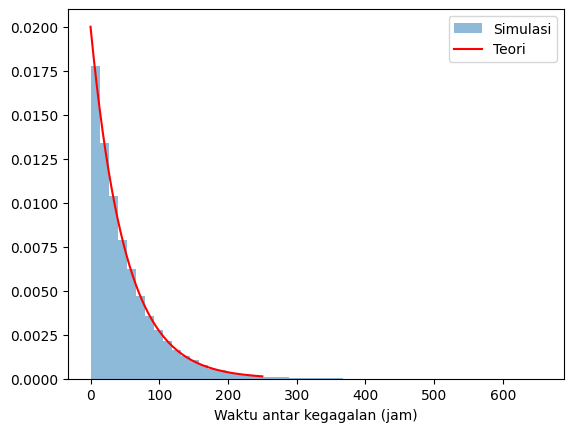

In [18]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.stats import expon

X = expon(scale=50)
print("P(X > 80) =", round(X.sf(80), 4))
print("P(X < 30) =", round(X.cdf(30), 4))
print("P(X>100 | X>50) =", round(X.sf(100) / X.sf(50), 4), "(= P(X>50) =",
      round(X.sf(50), 4), ")")

x = sp.symbols("x", positive=True)
f = sp.Rational(1, 50) * sp.exp(-x / 50)
E = sp.integrate(x * f, (x, 0, sp.oo))
V = sp.integrate(x**2 * f, (x, 0, sp.oo)) - E**2
print("Sympy: E(X) =", E, "| Var(X) =", V)
sim = np.random.default_rng(9).exponential(50, 100000)
print("Simulasi: rata-rata =", round(sim.mean(), 2),
      "| varians =", round(sim.var(), 1))

t = np.linspace(0, 250, 400)
plt.hist(sim, bins=50, density=True, alpha=0.5, label="Simulasi")
plt.plot(t, X.pdf(t), color="red", label="Teori")
plt.xlabel("Waktu antar kegagalan (jam)")
plt.legend()
plt.show()

## B8. Uniform

P(X > 35) = 0.375
P(20 < X < 30) = 0.25
Rata-rata = 30.0
Varians = 133.3333


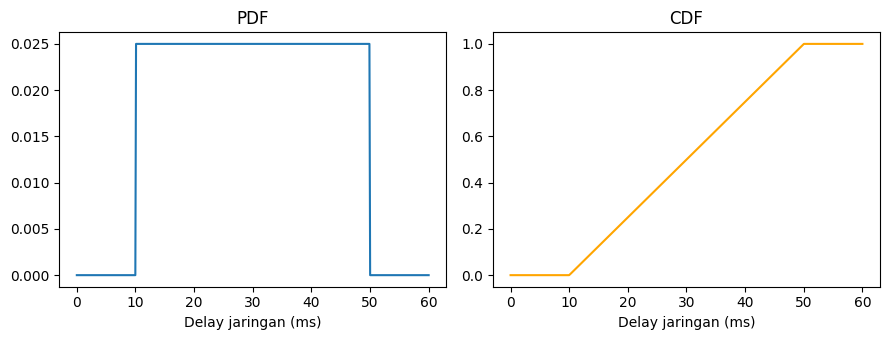

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform

X = uniform(loc=10, scale=40)
print("P(X > 35) =", round(X.sf(35), 4))
print("P(20 < X < 30) =", round(X.cdf(30) - X.cdf(20), 4))
print("Rata-rata =", X.mean())
print("Varians =", round(X.var(), 4))

x = np.linspace(0, 60, 500)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(x, X.pdf(x))
ax[0].set_title("PDF")
ax[1].plot(x, X.cdf(x), color="orange")
ax[1].set_title("CDF")
for a in ax:
    a.set_xlabel("Delay jaringan (ms)")
plt.tight_layout()
plt.show()

## B9. Gamma

P(X < 5) = 0.4562
P(X > 10) = 0.1247
Rata-rata = 6.0 | Varians = 12.0
Simulasi : P(X<5) = 0.454 | rata-rata = 6.011


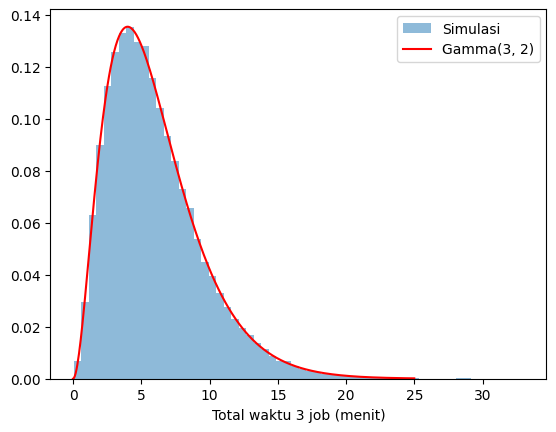

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma

X = gamma(a=3, scale=2)
print("P(X < 5) =", round(X.cdf(5), 4))
print("P(X > 10) =", round(X.sf(10), 4))
print("Rata-rata =", X.mean(), "| Varians =", X.var())
rng = np.random.default_rng(11)
sim = rng.exponential(2, (100000, 3)).sum(axis=1)
print("Simulasi : P(X<5) =", round((sim < 5).mean(), 4),
      "| rata-rata =", round(sim.mean(), 3))

t = np.linspace(0, 25, 400)
plt.hist(sim, bins=60, density=True, alpha=0.5, label="Simulasi")
plt.plot(t, X.pdf(t), color="red", label="Gamma(3, 2)")
plt.xlabel("Total waktu 3 job (menit)")
plt.legend()
plt.show()

## B10. Central Limit Theorem

n= 1 | rata-rata=1.016 | std=1.008 | teori std=1.000
n= 5 | rata-rata=0.997 | std=0.443 | teori std=0.447
n=30 | rata-rata=1.002 | std=0.186 | teori std=0.183


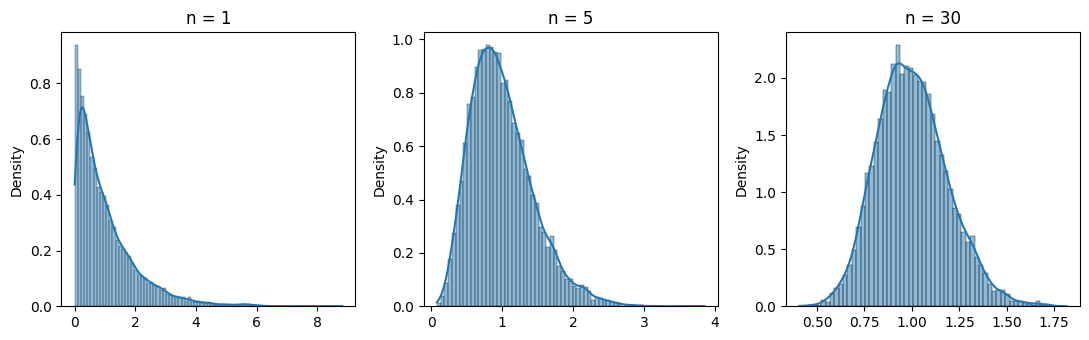

In [21]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

rng = np.random.default_rng(12)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.5))
for a, n in zip(ax, [1, 5, 30]):
    rata = rng.exponential(1, (10000, n)).mean(axis=1)
    sns.histplot(rata, kde=True, stat="density", ax=a)
    a.set_title(f"n = {n}")
    print(f"n={n:2d} | rata-rata={rata.mean():.3f} | "
          f"std={rata.std():.3f} | teori std={1/np.sqrt(n):.3f}")
plt.tight_layout()
plt.show()

## B11. Pendekatan normal untuk binomial

P(X <= 55) binomial persis = 0.8644
Normal tanpa koreksi       = 0.8413
Normal dengan koreksi 0.5  = 0.8643


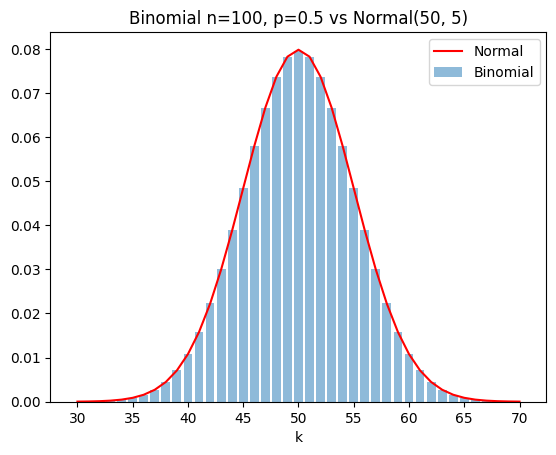

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

n, p = 100, 0.5
mu, sd = n * p, np.sqrt(n * p * (1 - p))
print("P(X <= 55) binomial persis =", round(binom.cdf(55, n, p), 4))
print("Normal tanpa koreksi       =", round(norm.cdf(55, mu, sd), 4))
print("Normal dengan koreksi 0.5  =", round(norm.cdf(55.5, mu, sd), 4))

k = np.arange(30, 71)
plt.bar(k, binom.pmf(k, n, p), alpha=0.5, label="Binomial")
plt.plot(k, norm.pdf(k, mu, sd), color="red", label="Normal")
plt.xlabel("k")
plt.legend()
plt.title("Binomial n=100, p=0.5 vs Normal(50, 5)")
plt.show()

## 5.2 Perbandingan E[X] dan Var(X)

In [23]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
N = 100000

# urutan pengambilan data acak (penting supaya hasil sama dengan laporan)
sim_binom = rng.binomial(10, 0.25, N)
sim_pois = rng.poisson(4, N)
sim_geom = rng.geometric(0.7, N)
sim_nbin = rng.negative_binomial(3, 0.4, N) + 3
sim_hiper = rng.hypergeometric(5, 15, 4, N)
sim_norm = rng.normal(200, 30, N)
sim_expo = rng.exponential(50, N)
sim_unif = rng.uniform(10, 50, N)
sim_gamma = rng.gamma(3, 2, N)

daftar = [
    ("Binomial(10; 0,25)", stats.binom(10, 0.25), sim_binom),
    ("Poisson(4)", stats.poisson(4), sim_pois),
    ("Geometrik(0,7)", stats.geom(0.7), sim_geom),
    ("Binom. Negatif(3; 0,4)", stats.nbinom(3, 0.4, loc=3), sim_nbin),
    ("Hipergeometrik(20,5,4)", stats.hypergeom(20, 5, 4), sim_hiper),
    ("Normal(200; 30)", stats.norm(200, 30), sim_norm),
    ("Uniform(10; 50)", stats.uniform(10, 40), sim_unif),
    ("Eksponensial(mean 50)", stats.expon(scale=50), sim_expo),
    ("Gamma(3; 2)", stats.gamma(3, scale=2), sim_gamma),
]

print(f"{'Distribusi':24s}{'E teori':>9s}{'E sim':>9s}{'Var teori':>11s}{'Var sim':>10s}")
for nama, d, s in daftar:
    print(f"{nama:24s}{d.mean():9.4f}{s.mean():9.4f}{d.var():11.4f}{s.var():10.4f}")

Distribusi                E teori    E sim  Var teori   Var sim
Binomial(10; 0,25)         2.5000   2.5024     1.8750    1.8772
Poisson(4)                 4.0000   3.9963     4.0000    3.9602
Geometrik(0,7)             1.4286   1.4289     0.6122    0.6106
Binom. Negatif(3; 0,4)     7.5000   7.5198    11.2500   11.1877
Hipergeometrik(20,5,4)     1.0000   0.9977     0.6316    0.6330
Normal(200; 30)          200.0000 199.9675   900.0000  902.1288
Uniform(10; 50)           30.0000  29.9901   133.3333  133.0656
Eksponensial(mean 50)     50.0000  50.2170  2500.0000 2522.4719
Gamma(3; 2)                6.0000   6.0180    12.0000   12.1079
